# Analisis Pendapatan Transaksi POS (2024–2025)

Tugas Pengantar Sains Data:
1. Membaca dataset transaksi POS (`paket_a_transaksi_pos_2024_2025.csv`).
2. Melakukan pembersihan data (menangani duplikat, missing value, format harga, dan tanggal).
3. Validasi anomali input pada kolom jumlah serta penanganan aturan status transaksi dan diskon.
4. Menghitung total pendapatan per tahun untuk tahun 2024 dan 2025.
5. Menyimpan ringkasan hasil ke file CSV.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# baca dataset
df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv", dtype=str)
print("Ukuran data awal:", df.shape)
df.head()


Ukuran data awal: (5030, 9)


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


## 1. Eksplorasi Awal dan Missing Value

In [2]:
# cek baris duplikat
print("Jumlah duplikat persis:", df.duplicated().sum())

# cek missing value di setiap kolom
print("\nMissing value per kolom:")
print(df.isna().sum())

# cek distribusi status dan diskon
print("\nDistribusi status:")
print(df["status"].value_counts())

print("\nDistribusi diskon (%):")
print(df["diskon_persen"].value_counts())


Jumlah duplikat persis: 30

Missing value per kolom:
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64

Distribusi status:
status
SELESAI    4749
BATAL       191
RETUR        90
Name: count, dtype: int64

Distribusi diskon (%):
diskon_persen
0     3848
10     420
5      346
15     271
20     145
Name: count, dtype: int64


## 2. Pembersihan Data (Data Cleaning)
- Hapus baris duplikat persis.
- Kolom `kode_kasir` yang kosong diisi `'TIDAK_DIKETAHUI'` agar data penjualan tetap lengkap.
- Format `tanggal` diseragamkan dan diekstrak kolom `tahun`.
- Format `harga_satuan` dibersihkan dari titik ribuan dan koma desimal, lalu diubah ke numerik.
- Ubah tipe data `jumlah` dan `diskon_persen` ke integer.


In [3]:
# 1. hapus duplikat
df = df.drop_duplicates().reset_index(drop=True)

# 2. tangani missing value kode_kasir
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK_DIKETAHUI")

# 3. seragamkan format tanggal
df["tanggal"] = pd.to_datetime(df["tanggal"], format="mixed", dayfirst=True)
df["tahun"] = df["tanggal"].dt.year

# 4. bersihkan format harga_satuan (contoh: '7500,00' -> 7500, '13.500' -> 13500)
def bersihkan_harga(val):
    s = str(val).strip()
    if "," in s:
        s = s.replace(".", "").replace(",", ".")
    else:
        s = s.replace(".", "")
    return float(s)

df["harga_satuan"] = df["harga_satuan"].map(bersihkan_harga)

# 5. ubah tipe data angka
df["jumlah"] = df["jumlah"].astype(int)
df["diskon_persen"] = df["diskon_persen"].astype(int)

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id_transaksi   5000 non-null   str           
 1   tanggal        5000 non-null   datetime64[us]
 2   kode_gerai     5000 non-null   str           
 3   kode_kasir     5000 non-null   str           
 4   kode_produk    5000 non-null   str           
 5   jumlah         5000 non-null   int64         
 6   harga_satuan   5000 non-null   float64       
 7   diskon_persen  5000 non-null   int64         
 8   status         5000 non-null   str           
 9   tahun          5000 non-null   int32         
dtypes: datetime64[us](1), float64(1), int32(1), int64(2), str(5)
memory usage: 371.2 KB


## 3. Pengecekan Anomali Kolom `jumlah`
Dalam transaksi kasir POS ritel/minimarket, kuantitas pembelian normal berkisar antara 1 sampai 12 unit (eceran atau lusin).
Jika kita cek kolom `jumlah`, ditemukan:
- Nilai negatif (-12 s/d -1)
- Nilai ekstrem ribuan (641 s/d 2375) yang merupakan anomali / salah input kasir.
Nilai anomali ini harus dikeluarkan agar tidak merusak perhitungan pendapatan riil toko.


In [4]:
print("Sebaran nilai jumlah:")
print(df["jumlah"].value_counts().sort_index())

# tandai jumlah yang wajar (1 sampai 12)
df["jumlah_valid"] = (df["jumlah"] > 0) & (df["jumlah"] <= 12)
print("\nJumlah baris anomali yang ditemukan:", (~df["jumlah_valid"]).sum())


Sebaran nilai jumlah:
jumlah
-12         2
-6          2
-4          4
-3          4
-2         12
-1         16
 1       1956
 2       1211
 3        743
 4        535
 6        353
 12       150
 641        1
 661        1
 746        1
 759        1
 892        1
 1280       1
 1301       1
 1310       1
 1456       1
 1983       1
 2093       1
 2375       1
Name: count, dtype: int64

Jumlah baris anomali yang ditemukan: 52


## 4. Perhitungan Pendapatan (Status dan Diskon)
Aturan bisnis:
- Hanya transaksi dengan status `SELESAI` yang diakui sebagai pendapatan sah (`BATAL` dan `RETUR` tidak dihitung).
- Pendapatan dihitung setelah dipotong diskon:
  `pendapatan_kotor = jumlah * harga_satuan`
  `pendapatan_bersih = pendapatan_kotor * (1 - diskon_persen / 100)`


In [5]:
# hitung pendapatan kotor dan bersih
df["pendapatan_kotor"] = df["jumlah"] * df["harga_satuan"]
df["pendapatan_bersih"] = df["pendapatan_kotor"] * (1 - df["diskon_persen"] / 100)

# filter data yang valid (status SELESAI dan jumlah wajar)
data_valid = df[(df["status"] == "SELESAI") & df["jumlah_valid"]].copy()
print(f"Data valid yang digunakan: {len(data_valid)} dari {len(df)} baris")


Data valid yang digunakan: 4672 dari 5000 baris


## 5. Hasil Pendapatan per Tahun (2024 dan 2025)

In [6]:
# agregasi per tahun
rekap = data_valid.groupby("tahun").agg(
    jumlah_transaksi=("id_transaksi", "count"),
    total_barang=("jumlah", "sum"),
    pendapatan_kotor=("pendapatan_kotor", "sum"),
    pendapatan_bersih=("pendapatan_bersih", "sum")
).reset_index()

rekap["total_diskon"] = rekap["pendapatan_kotor"] - rekap["pendapatan_bersih"]

# tabel tampilan dengan format rupiah
tampil = rekap.copy()
for col in ["pendapatan_kotor", "total_diskon", "pendapatan_bersih"]:
    tampil[col] = tampil[col].map(lambda x: f"Rp {x:,.0f}".replace(",", "."))

tampil


,tahun,jumlah_transaksi,total_barang,pendapatan_kotor,pendapatan_bersih,total_diskon
0,2024,2327,5967,Rp 130.883.500,Rp 127.406.475,Rp 3.477.025
1,2025,2345,6050,Rp 138.664.000,Rp 135.001.100,Rp 3.662.900


In [7]:
# cetak ringkasan sederhana
for _, r in rekap.iterrows():
    tahun = int(r["tahun"])
    bersih = f"Rp {r['pendapatan_bersih']:,.0f}".replace(",", ".")
    print(f"Pendapatan bersih tahun {tahun}: {bersih}")


Pendapatan bersih tahun 2024: Rp 127.406.475
Pendapatan bersih tahun 2025: Rp 135.001.100


## 6. Visualisasi Grafik

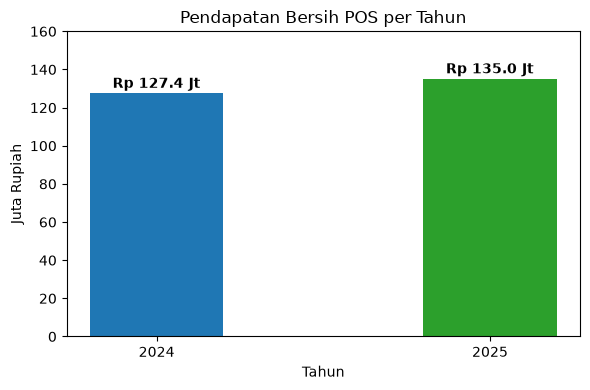

In [8]:
plt.figure(figsize=(6, 4))
bars = plt.bar(rekap["tahun"].astype(str), rekap["pendapatan_bersih"] / 1_000_000, color=["#1f77b4", "#2ca02c"], width=0.4)
plt.title("Pendapatan Bersih POS per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Juta Rupiah")
plt.ylim(0, 160)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, y + 3, f"Rp {y:,.1f} Jt", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("grafik_pendapatan_per_tahun.png", dpi=150)
plt.show()


## 7. Simpan Hasil ke CSV

In [9]:
rekap.to_csv("hasil_pendapatan_per_tahun.csv", index=False)
print("Hasil berhasil disimpan ke 'hasil_pendapatan_per_tahun.csv'")


Hasil berhasil disimpan ke 'hasil_pendapatan_per_tahun.csv'
